## 0. Imports, settings, loading the data

In [1]:
import os
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
from scipy.sparse.linalg import svds
from scipy.spatial.distance import cdist
from sklearn.model_selection import train_test_split
import pandas as pd

plt.rcParams["figure.figsize"] = [8, 8]
plt.rcParams.update({"font.size": 14})

DATA_PATH = None      # set to e.g. r"C:\data\allFaces.mat" if the file is elsewhere
DOWNSAMPLE = 2      # 1 = full 192x168 images; 2 or 4 = keep every 2nd / 4th pixel (faster, less memory)

In [2]:
candidates = [DATA_PATH, "allFaces.mat", os.path.join("DATA", "allFaces.mat"), os.path.join("..", "DATA", "allFaces.mat")]
path = next((p for p in candidates if p and os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError("allFaces.mat not found. Put it next to this notebook or set DATA_PATH.")

mat_contents = scipy.io.loadmat(path)
faces = np.asarray(mat_contents["faces"], dtype=np.float64)
m = int(mat_contents["m"].item())                 # image "height" as stored by the book's code
n = int(mat_contents["n"].item())                 # image "width"
nfaces = np.ndarray.flatten(mat_contents["nfaces"])   # images per person

if DOWNSAMPLE > 1:
    d = DOWNSAMPLE
    imgs = faces.T.reshape(-1, m, n)[:, ::d, ::d]
    m, n = imgs.shape[1:]
    faces = imgs.reshape(imgs.shape[0], -1).T.copy()

print("faces matrix:", faces.shape, "(pixels x images)")
print("m, n =", m, n, "| people:", len(nfaces), "| images per person: min", nfaces.min(), "max", nfaces.max())

def as_image(v):
    # the book stores each image as a column vector; reshape to (m, n) and transpose to display upright
    return np.reshape(v, (m, n)).T

faces matrix: (8064, 2410) (pixels x images)
m, n = 84 96 | people: 38 | images per person: min 59 max 64


## 1. Look at the data
First image of each of the first 36 people, then all lighting conditions of one person.

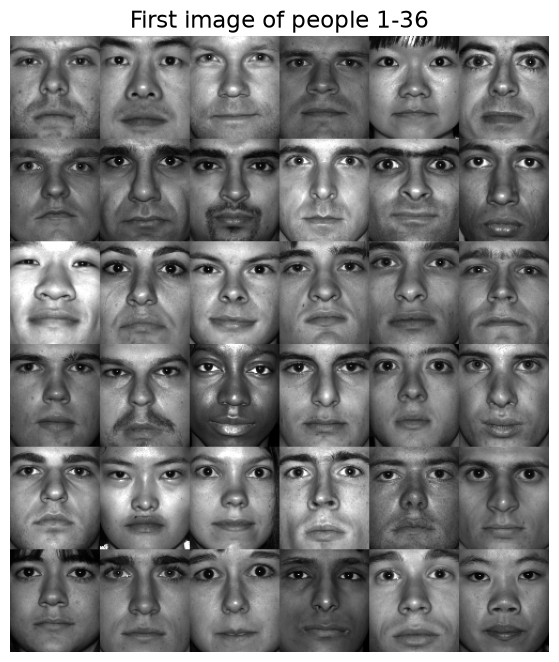

In [3]:
allPersons = np.zeros((n * 6, m * 6))
count = 0
for j in range(6):
    for k in range(6):
        allPersons[j * n:(j + 1) * n, k * m:(k + 1) * m] = as_image(faces[:, np.sum(nfaces[:count])])
        count += 1
img = plt.imshow(allPersons)
img.set_cmap("gray")
plt.axis("off")
plt.title("First image of people 1-36")
plt.show()

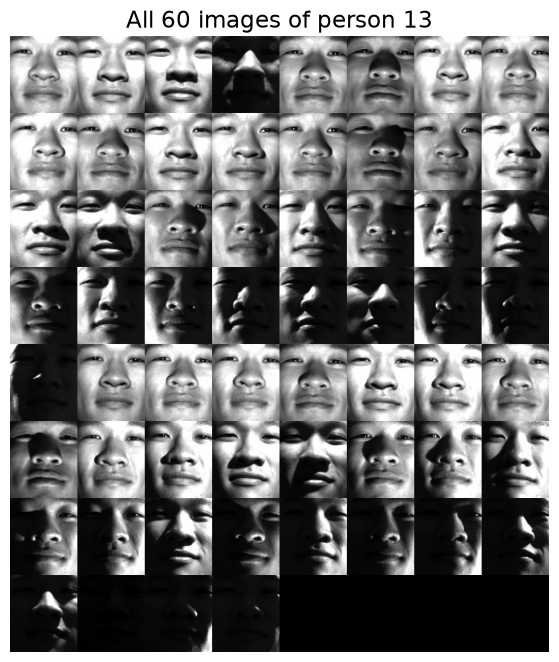

In [4]:
Person = 12  # change this (0 to 37) to look at another person; each person has ~64 lighting conditions
subset = faces[:, np.sum(nfaces[:Person]):np.sum(nfaces[:(Person + 1)])]
allFaces = np.zeros((n * 8, m * 8))
count = 0
for j in range(8):
    for k in range(8):
        if count < nfaces[Person]:
            allFaces[j * n:(j + 1) * n, k * m:(k + 1) * m] = as_image(subset[:, count])
            count += 1
img = plt.imshow(allFaces)
img.set_cmap("gray")
plt.axis("off")
plt.title(f"All {nfaces[Person]} images of person {Person + 1}")
plt.show()

## 2. Mean face and eigenfaces
The book trains on the **first 36 people** and keeps the last two people (37 and 38) as unseen test subjects.
$\mu$ = average training face, $X = $ training faces $-\ \mu$, and $X = U\Sigma V^T$. Columns of $U$ are the eigenfaces.

training images N = 2282 | U: (8064, 2282) | S: (2282,)


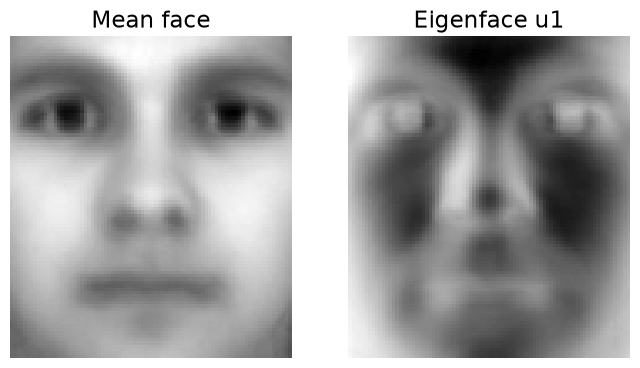

In [5]:
# We use the first 36 people for training data
trainingFaces = faces[:, :np.sum(nfaces[:36])]
avgFace = np.mean(trainingFaces, axis=1)            # length m*n

# Compute eigenfaces on mean-subtracted training data
X = trainingFaces - avgFace[:, None]                # same as the book's np.tile(...).T
U, S, VT = np.linalg.svd(X, full_matrices=0)
print("training images N =", X.shape[1], "| U:", U.shape, "| S:", S.shape)

fig1 = plt.figure()
ax1 = fig1.add_subplot(121)
img_avg = ax1.imshow(as_image(avgFace))
img_avg.set_cmap("gray")
plt.axis("off"); plt.title("Mean face")

ax2 = fig1.add_subplot(122)
img_u1 = ax2.imshow(as_image(U[:, 0]))
img_u1.set_cmap("gray")
plt.axis("off"); plt.title("Eigenface u1")
plt.show()

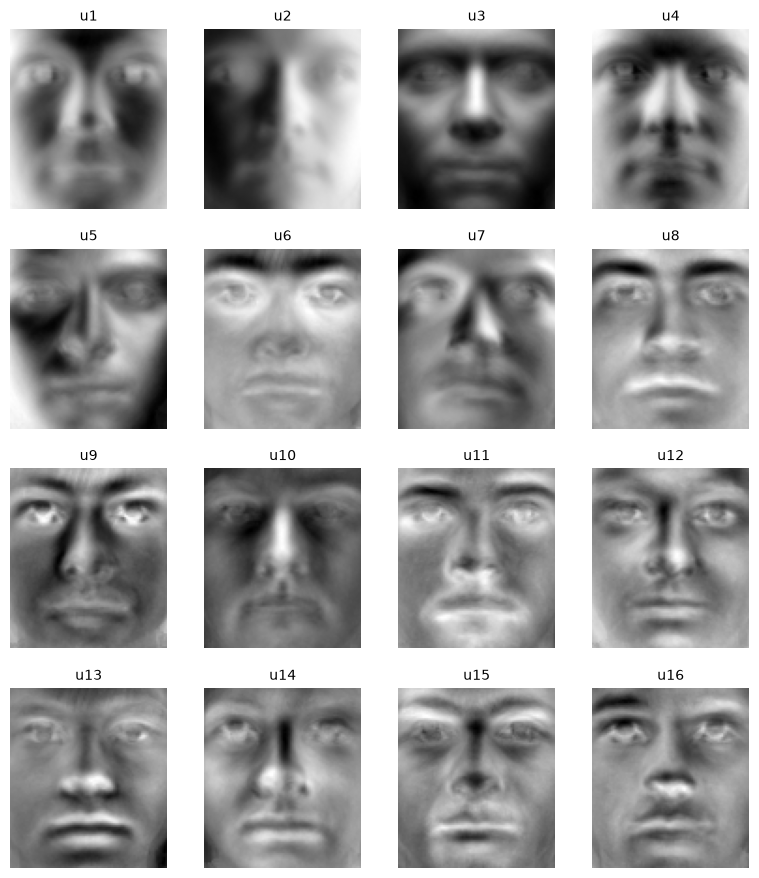

In [6]:
# extra: the first 16 eigenfaces
fig, axes = plt.subplots(4, 4, figsize=(8, 9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(as_image(U[:, i]), cmap="gray"); ax.set_title(f"u{i + 1}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Singular values and energy

eigenfaces needed for 90% / 95% / 99% of the energy: 22 / 61 / 287   (M = 2282)

 M_prime  sigma_M_prime  cumulative energy
      25       12506.32             90.73%
      50        7876.11             94.21%
     100        4663.60             96.82%
     200        2461.37             98.47%
     400        1237.96             99.35%
     800         610.05             99.78%
    1600         242.78             99.97%


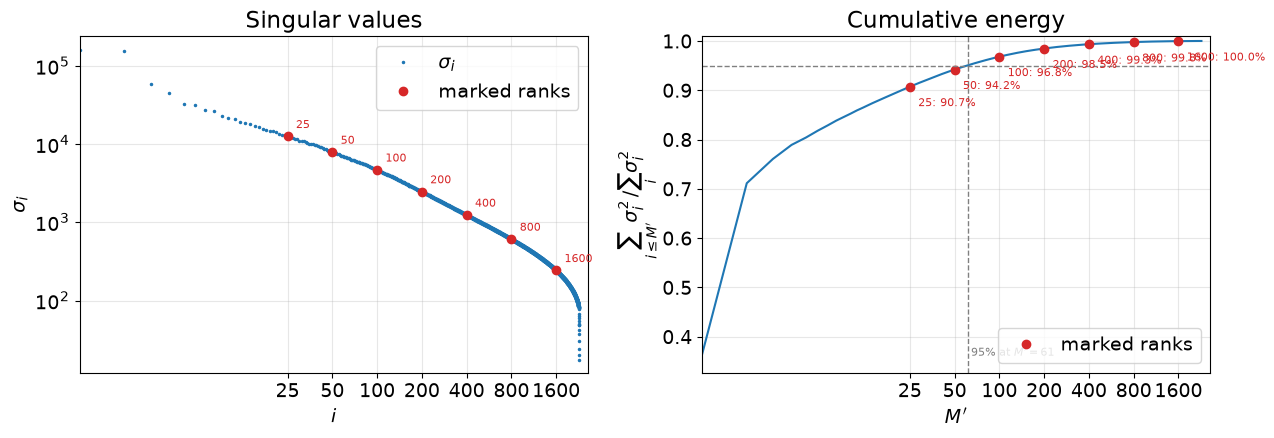

smallest / largest singular value: 8.422465342136735e-17 (about 0 because centered data has rank <= M-1)


In [7]:
from matplotlib.ticker import ScalarFormatter

# S = singular values of the CENTERED matrix A, X = data matrix (columns = images)
M = X.shape[1]
i_all = np.arange(1, len(S) + 1)
pts = np.array([25, 50, 100, 200, 400, 800, 1600])
pts = pts[pts <= len(S)]
LOG_X = True                                     # False -> linear axis, ticks every 200

cum = np.cumsum(S**2) / np.sum(S**2)
k90 = int(np.searchsorted(cum, 0.90)) + 1
k95 = int(np.searchsorted(cum, 0.95)) + 1
k99 = int(np.searchsorted(cum, 0.99)) + 1
print(f"eigenfaces needed for 90% / 95% / 99% of the energy: {k90} / {k95} / {k99}   (M = {M})")

print(f"\n{'M_prime':>8} {'sigma_M_prime':>14} {'cumulative energy':>18}")
for p in pts:
    print(f"{p:8d} {S[p-1]:14.2f} {100*cum[p-1]:17.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

# --- left: singular values ---
ax[0].semilogy(i_all, S, ".", ms=3, color="tab:blue", label=r"$\sigma_i$")
ax[0].plot(pts, S[pts - 1], "o", color="tab:red", ms=6, label="marked ranks")
for j, p in enumerate(pts):
    ax[0].annotate(str(p), (p, S[p - 1]), textcoords="offset points",
                   xytext=(6, 6 + (0 if LOG_X else 12 * (j % 2))), fontsize=8, color="tab:red")
ax[0].set_title("Singular values")
ax[0].set_xlabel("$i$"); ax[0].set_ylabel(r"$\sigma_i$"); ax[0].legend()

# --- right: cumulative energy ---
ax[1].plot(i_all, cum, color="tab:blue")
ax[1].plot(pts, cum[pts - 1], "o", color="tab:red", ms=6, label="marked ranks")
for j, p in enumerate(pts):
    ax[1].annotate(f"{p}: {100*cum[p-1]:.1f}%", (p, cum[p - 1]), textcoords="offset points",
                   xytext=(6, -14 - (0 if LOG_X else 12 * (j % 2))), fontsize=8, color="tab:red")
ax[1].axhline(0.95, color="gray", ls="--", lw=1)
ax[1].axvline(k95, color="gray", ls="--", lw=1)
ax[1].text(k95, 0.05, f" 95% at $M'={k95}$", fontsize=8, color="gray", transform=ax[1].get_xaxis_transform())
ax[1].set_title("Cumulative energy")
ax[1].set_xlabel("$M'$"); ax[1].set_ylabel(r"$\sum_{i\leq M'}\sigma_i^2\,/\sum_i\sigma_i^2$"); ax[1].legend(loc="lower right")

# --- x-axis ticks and zoom (the NEW block replaces the old ticks block) ---
for a in ax:
    if LOG_X:
        a.set_xscale("log"); a.set_xticks(pts)
        a.xaxis.set_major_formatter(ScalarFormatter()); a.minorticks_off()
        a.set_xlim(1, len(S) * 1.15)
    else:
        a.set_xticks(np.arange(0, len(S) + 1, 200)); a.tick_params(axis="x", labelrotation=45)
        a.set_xlim(0, len(S) * 1.03)
    a.margins(x=0)
    a.grid(alpha=0.3)

ax[0].set_ylim(S[:-1].min() * 0.7, S.max() * 1.5)
ax[1].set_ylim(cum[0] * 0.9, 1.01)

plt.tight_layout(); plt.show()
print("smallest / largest singular value:", S[-1] / S[0],
      "(about 0 because centered data has rank <= M-1)")

## 4. Reconstruct a face of an unseen person
Person 37 was **not** used to build the eigenfaces. Project the mean-subtracted face onto the first r eigenfaces and add the mean back:
$\hat x = \mu + U_r U_r^T (x - \mu)$

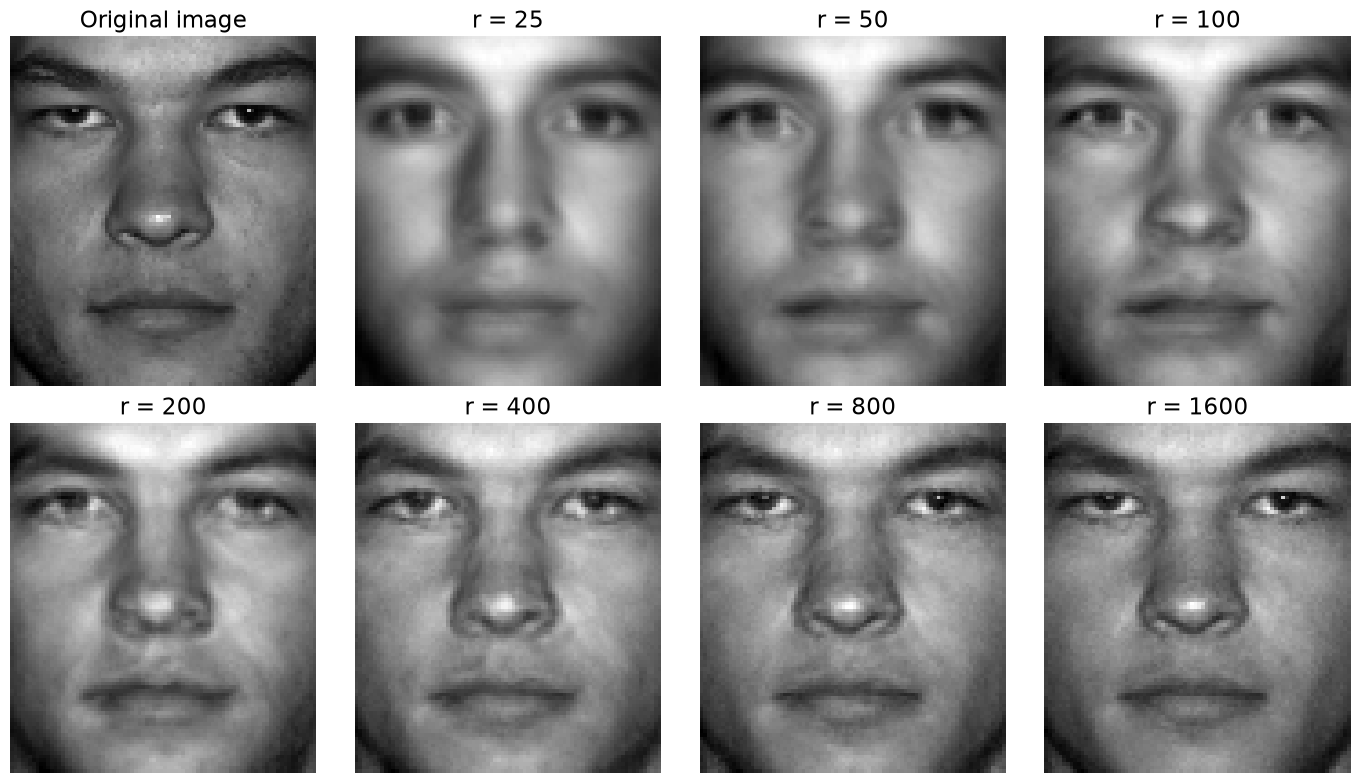

In [8]:
## Now show eigenface reconstruction of image that was omitted from test set
testFace = faces[:, np.sum(nfaces[:36])]            # First face of person 37
testFaceMS = testFace - avgFace
r_list = [25, 50, 100, 200, 400, 800, 1600]
r_list = [r for r in r_list if r <= U.shape[1]]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
axes = axes.ravel()
axes[0].imshow(as_image(testFace), cmap="gray"); axes[0].set_title("Original image"); axes[0].axis("off")
for ax, r in zip(axes[1:], r_list):
    reconFace = avgFace + U[:, :r] @ U[:, :r].T @ testFaceMS
    ax.imshow(as_image(reconFace), cmap="gray"); ax.set_title(f"r = {r}"); ax.axis("off")
for ax in axes[1 + len(r_list):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

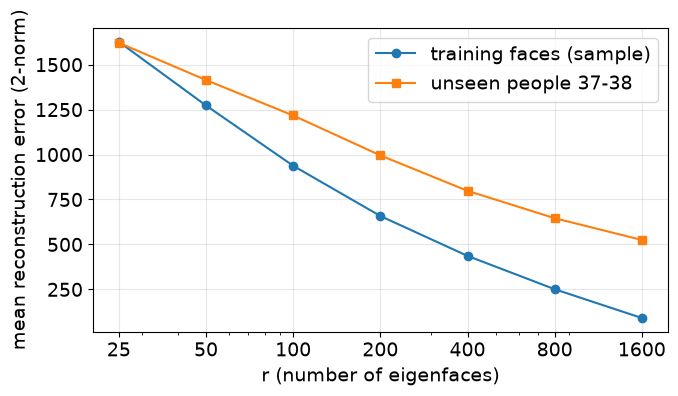


Numerical Data:
 r (Eigenfaces)  Training Error  Unseen Error
             25     1627.031425   1621.536921
             50     1272.862081   1414.295206
            100      937.444888   1217.155212
            200      658.084951    995.307002
            400      436.077069    798.051872
            800      250.861324    645.866340
           1600       90.601905    524.862689


In [9]:


# extra: reconstruction error vs r, for unseen people (37 and 38) and for a sample of training faces
rng = np.random.default_rng(0)
test_cols = faces[:, np.sum(nfaces[:36]):]
train_sample = trainingFaces[:, rng.choice(trainingFaces.shape[1], 150, replace=False)]

def mean_recon_error(Xq, r):
    Xc = Xq - avgFace[:, None]
    Ur = U[:, :r]
    return np.mean(np.linalg.norm(Xc - Ur @ (Ur.T @ Xc), axis=0))

rs = [r for r in [25, 50, 100, 200, 400, 800, 1600] if r <= U.shape[1]]

# Calculate the errors once and store them
train_errors = [mean_recon_error(train_sample, r) for r in rs]
test_errors = [mean_recon_error(test_cols, r) for r in rs]

# --- Plotting ---
plt.figure(figsize=(7, 4))
plt.plot(rs, train_errors, "o-", label="training faces (sample)")
plt.plot(rs, test_errors, "s-", label="unseen people 37-38")

plt.xscale("log")
plt.xticks(rs, labels=[str(r) for r in rs]) 
plt.xlabel("r (number of eigenfaces)")
plt.ylabel("mean reconstruction error (2-norm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- Table Generation ---
# Create a pandas DataFrame for a clean tabular display
error_table = pd.DataFrame({
    'r (Eigenfaces)': rs,
    'Training Error': train_errors,
    'Unseen Error': test_errors
})

print("\nNumerical Data:")
print(error_table.to_string(index=False))

## 5. Two people in the space of PC5 and PC6
Mean-subtract all images of person 2 and person 7 and look at their coordinates along two eigenfaces. Images of the same person cluster together, which is what makes recognition by nearest neighbour possible.

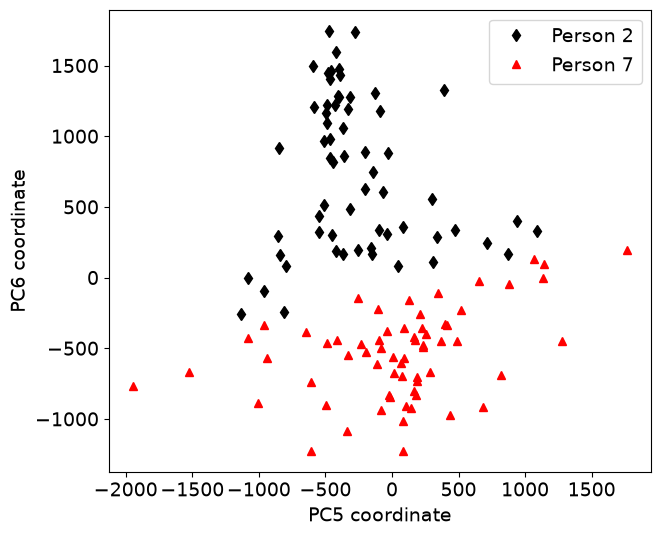

In [10]:
## Project person 2 and 7 onto PC5 and PC6
P1num = 2     # Person number 2
P2num = 7     # Person number 7

P1 = faces[:, np.sum(nfaces[:(P1num - 1)]):np.sum(nfaces[:P1num])]
P2 = faces[:, np.sum(nfaces[:(P2num - 1)]):np.sum(nfaces[:P2num])]

P1 = P1 - avgFace[:, None]
P2 = P2 - avgFace[:, None]

PCAmodes = np.array([5, 6])                      # Project onto PCA modes 5 and 6
PCACoordsP1 = U[:, PCAmodes - 1].T @ P1
PCACoordsP2 = U[:, PCAmodes - 1].T @ P2

plt.figure(figsize=(7, 6))
plt.plot(PCACoordsP1[0, :], PCACoordsP1[1, :], "d", color="k", label="Person 2")
plt.plot(PCACoordsP2[0, :], PCACoordsP2[1, :], "^", color="r", label="Person 7")
plt.xlabel("PC5 coordinate"); plt.ylabel("PC6 coordinate")
plt.legend(); plt.show()

## 6. Numerical check of Eckart–Young on this dataset
For the centered training matrix $X$ (rank ≤ N−1), with $X_r = U_r\Sigma_rV_r^T = U_rU_r^TX$:

$\|X-X_r\|_F = \sqrt{\sum_{i>r}\sigma_i^2}$ and $\|X-X_r\|_2 = \sigma_{r+1}$.

In [11]:
print(f"{'r':>5} | {'||X-Xr||_F':>14} | {'sqrt(sum s_i^2, i>r)':>22} | {'||X-Xr||_2':>14} | {'sigma_(r+1)':>12}")
for r in [25, 50, 100, 200, 400, 800, 1600]:
    Ur = U[:, :r]
    R = X - Ur @ (Ur.T @ X)                       # residual X - X_r
    fro = np.linalg.norm(R, "fro")
    spec = svds(R, k=1, return_singular_vectors=False)[0]    # largest singular value of the residual
    print(f"{r:>5} | {fro:>14.4f} | {np.sqrt(np.sum(S[r:]**2)):>22.4f} | {spec:>14.4f} | {S[r]:>12.4f}")

    r |     ||X-Xr||_F |   sqrt(sum s_i^2, i>r) |     ||X-Xr||_2 |  sigma_(r+1)
   25 |     80364.2751 |             80364.2751 |     12091.4510 |   12091.4510
   50 |     63523.6732 |             63523.6732 |      7797.1249 |    7797.1249
  100 |     47046.3420 |             47046.3420 |      4627.7733 |    4627.7733
  200 |     32612.2238 |             32612.2238 |      2443.4524 |    2443.4524
  400 |     21343.1070 |             21343.1070 |      1234.6405 |    1234.6405
  800 |     12256.2532 |             12256.2532 |       608.7516 |     608.7516
 1600 |      4371.6055 |              4371.6055 |       242.4567 |     242.4567


## 7. Recognition on Extended Yale B
The book only uses eigenfaces for reconstruction and visualization. To turn it into recognition, this section trains on **all 38 people**: 70 % of each person's images build the eigenfaces and the gallery, the other 30 % are test queries (nearest neighbour in eigenface coefficient space).

Extended Yale B has strong lighting changes, so the first few eigenfaces mostly encode illumination. A classic remedy (Belhumeur et al., 1997) is to discard the first few components. The code compares keeping all of the first r components against skipping the first 3.

train: (8064, 1687) | test: (8064, 723)


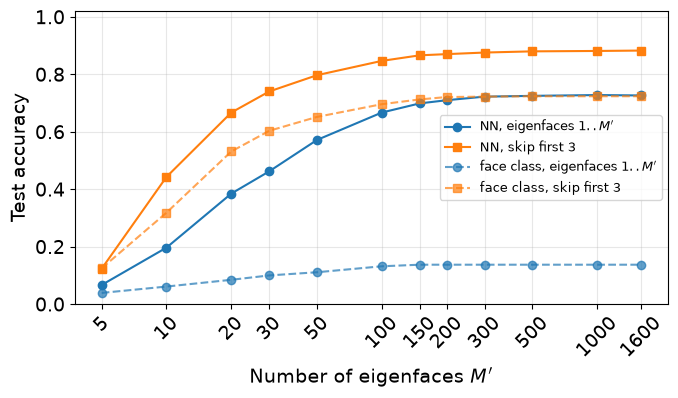

 M_prime |      NN  NN skip3 |   class  class skip3
       5 |   0.066     0.123 |   0.039        0.124
      10 |   0.196     0.443 |   0.061        0.318
      20 |   0.385     0.667 |   0.084        0.531
      30 |   0.462     0.740 |   0.100        0.603
      50 |   0.571     0.797 |   0.111        0.651
     100 |   0.667     0.846 |   0.131        0.696
     150 |   0.698     0.866 |   0.137        0.712
     200 |   0.710     0.870 |   0.137        0.721
     300 |   0.722     0.876 |   0.137        0.722
     500 |   0.725     0.880 |   0.137        0.723
    1000 |   0.728     0.881 |   0.137        0.723
    1600 |   0.726     0.882 |   0.137        0.723


In [12]:
import os
os.makedirs("figs", exist_ok=True)

labels = np.repeat(np.arange(len(nfaces)), nfaces)
idx = np.arange(faces.shape[1])
tr, te = train_test_split(idx, test_size=0.3, stratify=labels, random_state=0)

Xtr, Xte = faces[:, tr], faces[:, te]
ytr, yte = labels[tr], labels[te]
mu2 = Xtr.mean(axis=1, keepdims=True)
U2, S2, _ = np.linalg.svd(Xtr - mu2, full_matrices=False)    # eigenfaces from TRAINING images only
P = len(nfaces)                                              # number of people (38)
print("train:", Xtr.shape, "| test:", Xte.shape)

def accuracy(r, skip=0):
    """Return (nearest-neighbour accuracy, nearest-face-class accuracy) using eigenfaces skip+1..r."""
    Ur = U2[:, skip:r]
    Wtr = Ur.T @ (Xtr - mu2)                                 # training weight vectors
    Wte = Ur.T @ (Xte - mu2)                                 # test weight vectors
    # 1) nearest neighbour among all training images
    nn = cdist(Wte.T, Wtr.T).argmin(axis=1)
    acc_nn = np.mean(ytr[nn] == yte)
    # 2) nearest face class: Omega_k = mean weight vector of person k
    Om = np.stack([Wtr[:, ytr == p].mean(axis=1) for p in range(P)], axis=1)
    acc_cls = np.mean(cdist(Wte.T, Om.T).argmin(axis=1) == yte)
    return acc_nn, acc_cls

rs2 = [r for r in [5, 10, 20, 30, 50, 100, 150, 200, 300, 500, 1000, 1600, 2000] if r <= U2.shape[1]]
res_all  = np.array([accuracy(r)         for r in rs2])      # columns: [NN, face class]
res_skip = np.array([accuracy(r, skip=3) for r in rs2])

plt.figure(figsize=(7, 4.2))
plt.plot(rs2, res_all[:, 0],  "o-",  color="tab:blue",   label="NN, eigenfaces $1..M'$")
plt.plot(rs2, res_skip[:, 0], "s-",  color="tab:orange", label="NN, skip first 3")
plt.plot(rs2, res_all[:, 1],  "o--", color="tab:blue",   alpha=0.7, label="face class, eigenfaces $1..M'$")
plt.plot(rs2, res_skip[:, 1], "s--", color="tab:orange", alpha=0.7, label="face class, skip first 3")
plt.xscale("log"); plt.xticks(rs2, [str(r) for r in rs2], rotation=45)
plt.minorticks_off()
plt.xlabel("Number of eigenfaces $M'$"); plt.ylabel("Test accuracy"); plt.ylim(0, 1.02)
plt.legend(fontsize=9); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("figs/accuracy_vs_r.pdf", bbox_inches="tight")  # save BEFORE show
plt.show()

print(f"{'M_prime':>8} | {'NN':>7} {'NN skip3':>9} | {'class':>7} {'class skip3':>12}")
for r, a, b in zip(rs2, res_all, res_skip):
    print(f"{r:>8} | {a[0]:7.3f} {b[0]:9.3f} | {a[1]:7.3f} {b[1]:12.3f}")

# LaTeX table for the slide
with open("figs/acc_table.tex", "w") as f:
    f.write("\\begin{tabular}{rcccc}\\toprule\n")
    f.write(" & \\multicolumn{2}{c}{Nearest neighbour (\\%)} & \\multicolumn{2}{c}{Face class (\\%)} \\\\\n")
    f.write("$M'$ & $1..M'$ & skip 3 & $1..M'$ & skip 3 \\\\ \\midrule\n")
    for r, a, b in zip(rs2, res_all, res_skip):
        f.write(f"{r} & {100*a[0]:.1f} & {100*b[0]:.1f} & {100*a[1]:.1f} & {100*b[1]:.1f} \\\\\n")
    f.write("\\bottomrule\\end{tabular}\n")

## 8. Try your own photo
Run sections 2 and 4 first (this uses `avgFace`, `U`, `test_cols` and `mean_recon_error`). Put your photo next to the notebook and set `MY_IMAGE`.

**How to take/prepare the photo:** straight-on, face centred, eyes roughly level, neutral expression, no glasses or hat, even lighting (no strong shadow on one side), and crop tightly around the face like the Yale B images (little hair or background). The code converts to grayscale, crops to the training images' aspect ratio, resizes to exactly the training size and scales the brightness to the dataset range.

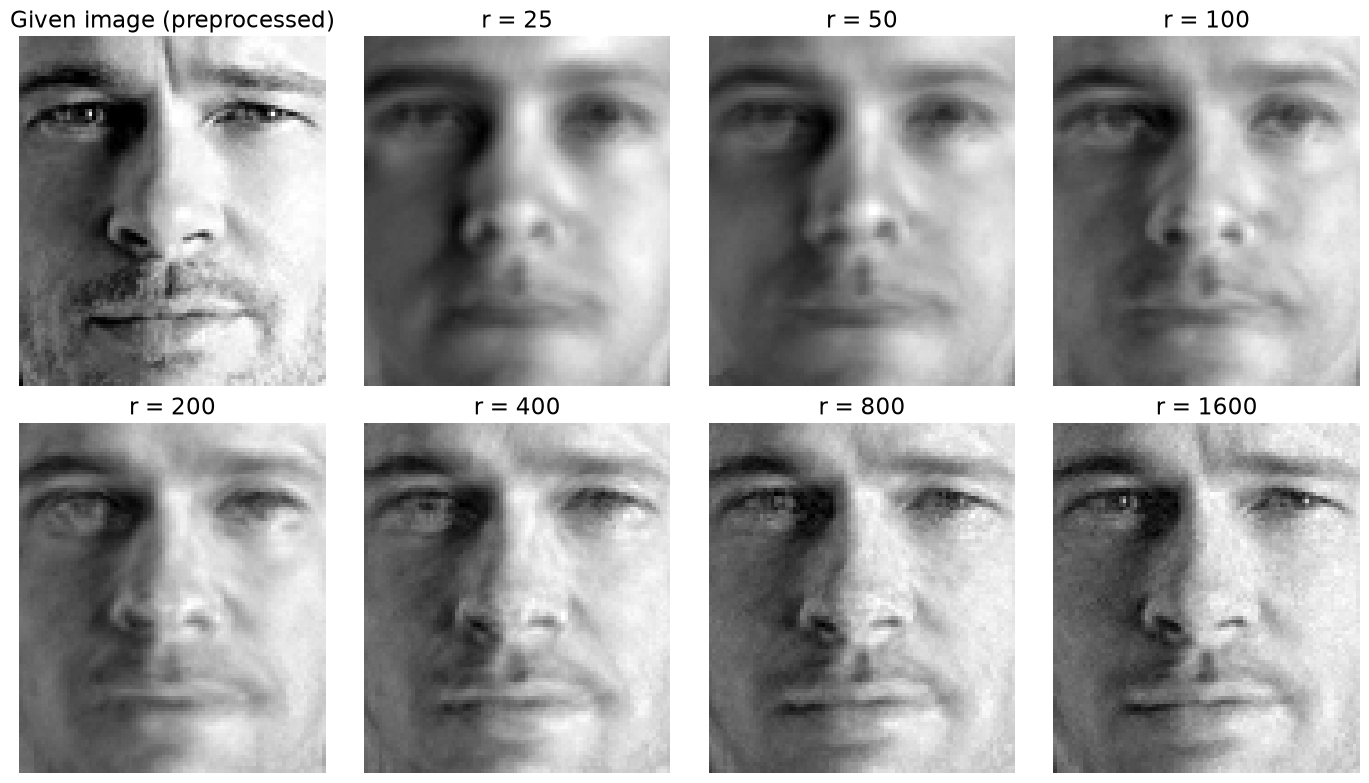

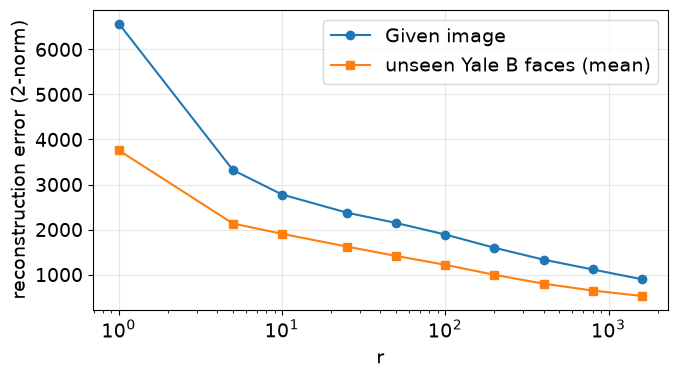

error ratio (yours / typical unseen Yale B face) at each r: [1.75 1.56 1.46 1.46 1.52 1.55 1.6  1.67 1.72 1.71]


In [13]:
from PIL import Image, ImageOps

MY_IMAGE = "brad_pitt.jpg"      # path to your photo
CENTER = None                 # (x, y) pixel position of the middle of your face in the ORIGINAL photo; None = centre of photo
CROP_WIDTH = None             # width in pixels of the region to keep around the face; None = as large as possible

rows, cols = as_image(faces[:, 0]).shape           # (height, width) of the images the model was trained on
img = ImageOps.exif_transpose(Image.open(MY_IMAGE)).convert("L")   # fix phone rotation, grayscale

# crop a box with the SAME aspect ratio as the training images (otherwise the face is squashed)
W0, H0 = img.size
target = cols / rows
cx, cy = CENTER if CENTER is not None else (W0 / 2, H0 / 2)
cw = CROP_WIDTH if CROP_WIDTH is not None else min(W0, H0 * target)
ch = cw / target
img = img.crop(tuple(int(round(b)) for b in (cx - cw / 2, cy - ch / 2, cx + cw / 2, cy + ch / 2)))

img = ImageOps.autocontrast(img, cutoff=1)          # optional: stretch contrast
img = img.resize((cols, rows), Image.LANCZOS)       # PIL takes (width, height)
my = np.asarray(img, dtype=np.float64) / 255.0 * faces.max()    # same intensity range as the dataset

x_me = my.T.reshape(-1)                             # exact inverse of as_image(): same pixel ordering as the dataset
x_me_ms = x_me - avgFace

# reconstruct with r eigenfaces
r_me = [r for r in [25, 50, 100, 200, 400, 800, 1600] if r <= U.shape[1]]
fig, axes = plt.subplots(2, 4, figsize=(14, 8)); axes = axes.ravel()
axes[0].imshow(my, cmap="gray"); axes[0].set_title("Given image (preprocessed)"); axes[0].axis("off")
for ax, r in zip(axes[1:], r_me):
    rec = avgFace + U[:, :r] @ (U[:, :r].T @ x_me_ms)
    ax.imshow(as_image(rec), cmap="gray"); ax.set_title(f"r = {r}"); ax.axis("off")
for ax in axes[1 + len(r_me):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

# how good is the fit compared with unseen Yale B faces (people 37-38)?
rs_me = [1, 5, 10, 25, 50, 100, 200, 400, 800, 1600]
rs_me = [r for r in rs_me if r <= U.shape[1]]
err_me = [np.linalg.norm(x_me_ms - U[:, :r] @ (U[:, :r].T @ x_me_ms)) for r in rs_me]
err_ref = [mean_recon_error(test_cols, r) for r in rs_me]
plt.figure(figsize=(7, 4))
plt.plot(rs_me, err_me, "o-", label="Given image")
plt.plot(rs_me, err_ref, "s-", label="unseen Yale B faces (mean)")
plt.xscale("log"); plt.xlabel("r"); plt.ylabel("reconstruction error (2-norm)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("error ratio (yours / typical unseen Yale B face) at each r:", np.round(np.array(err_me) / np.array(err_ref), 2))

## Notes for your report and slides
* Section 2 gives the mean face and eigenfaces; section 3 gives the energy plots used to choose r.
* Section 4 is the book's reconstruction experiment: faces of people never seen in training are still approximated well by a few hundred eigenfaces, and the error never reaches zero (unlike training faces).
* Section 5 shows why recognition is possible: images of one person form a cluster in eigenface coordinates.
* Section 6 verifies the Eckart–Young error formulas numerically on real data.
* Section 7 is my extension. Report your own numbers from the run, and say that the accuracy depends on the random split.

In [14]:
import numpy as np, scipy.io as sio
mat = sio.loadmat("allFaces.mat")
nfaces = mat["nfaces"].ravel()
print("persons:", len(nfaces), " total images:", nfaces.sum())
print("images per person:", nfaces)
print("first 36 people:", nfaces[:36].sum(), "  last 2 people:", nfaces[36:].sum())

persons: 38  total images: 2410
images per person: [64 62 64 64 62 64 64 64 64 64 60 59 60 63 62 63 63 64 64 64 64 64 64 64
 64 64 64 64 64 64 64 64 64 64 64 64 64 64]
first 36 people: 2282   last 2 people: 128
